In [44]:
import pandas as pd
df = pd.read_csv('../data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
print(df.shape)

(225745, 79)


In [45]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [46]:
print(df.columns.tolist())

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [47]:
df[' Label'].value_counts()

 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

In [48]:
total_bytes = df['Total Length of Fwd Packets'] + df[' Total Length of Bwd Packets']

In [49]:
bin_size = 100
binned = total_bytes.groupby(total_bytes.index // bin_size).sum()

In [50]:
print(binned.shape)
binned.head(10)

(2258,)


0      49515
1    8929652
2    9872469
3    7953854
4      87899
5      20393
6      20658
7    4410105
8     186830
9      34934
dtype: int64

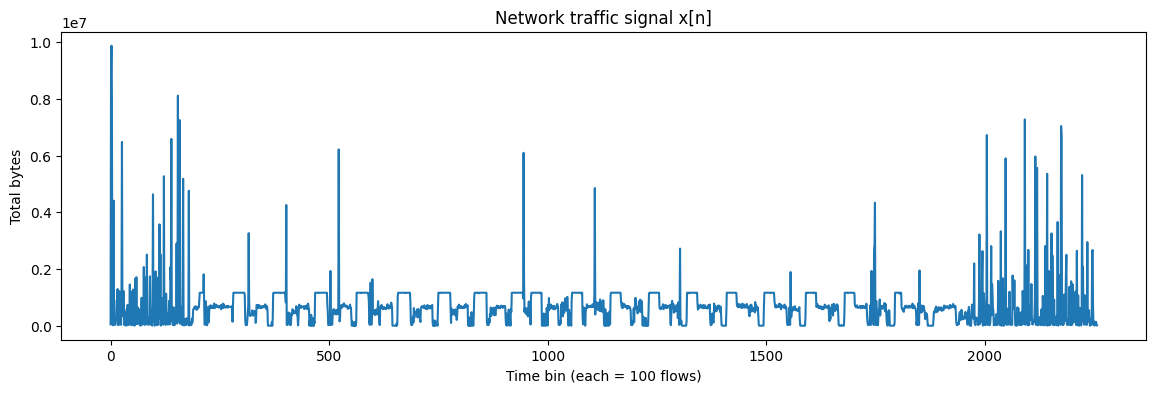

In [51]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14,4)) 
plt.plot(binned.values) 
plt.xlabel('Time bin (each = 100 flows)') 
plt.ylabel('Total bytes') 
plt.title('Network traffic signal x[n]') 
plt.show()

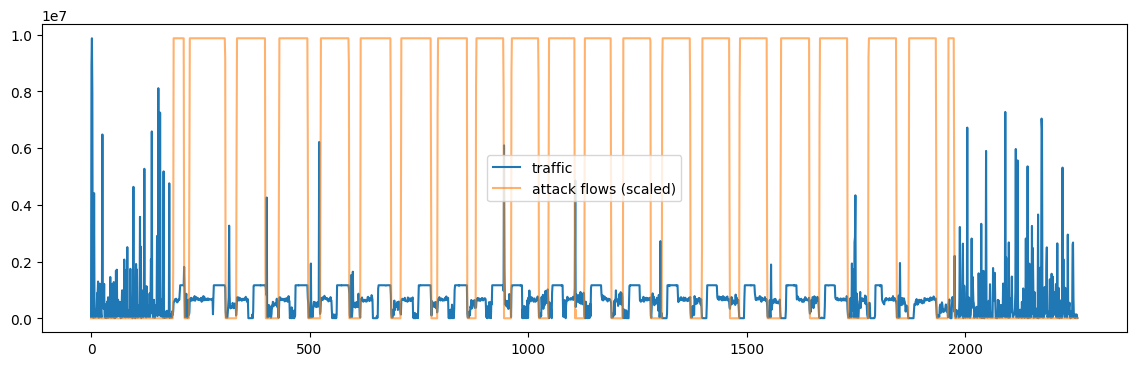

In [52]:
attack_mask = (df[' Label'] != 'BENIGN').groupby(df.index // bin_size).sum() 
plt.figure(figsize=(14,4)); 
plt.plot(binned.values, label='traffic'); 
plt.plot(attack_mask.values * (binned.max()/attack_mask.max()), label='attack flows (scaled)', alpha=0.6);
plt.legend(); 
plt.show()

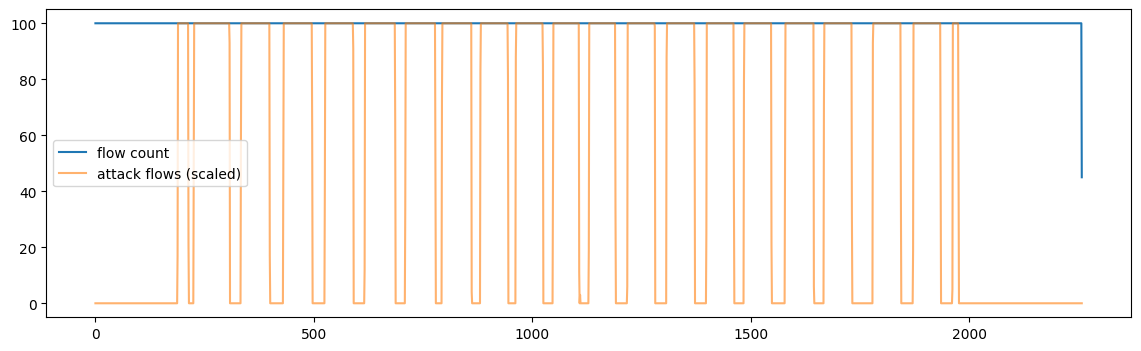

In [53]:
flow_count = df.groupby(df.index // bin_size).size()
plt.figure(figsize=(14,4))
plt.plot(flow_count.values, label='flow count')
plt.plot(attack_mask.values * (flow_count.max()/attack_mask.max()), label='attack flows (scaled)', alpha=0.6)
plt.legend()
plt.show()

In [54]:
packets = df[' Total Fwd Packets'] + df[' Total Backward Packets'] 
packet_signal = packets.groupby(df.index // bin_size).sum() 
print(packet_signal.shape)

(2258,)


In [55]:
duration_signal = df[' Flow Duration'].groupby(df.index // bin_size).mean()
print(duration_signal.shape)

(2258,)


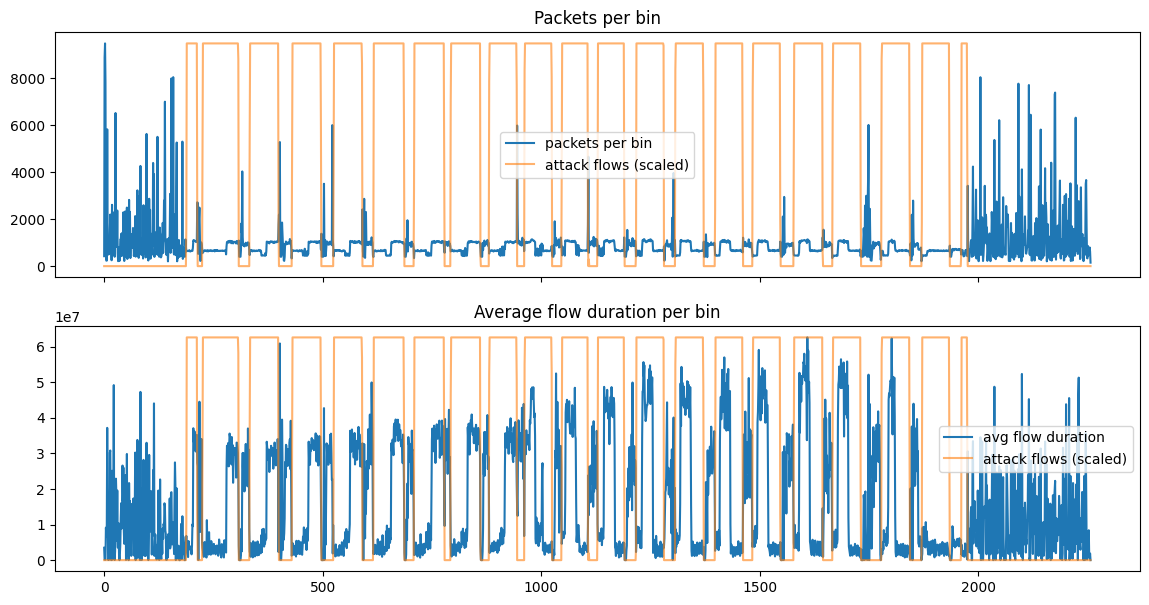

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(packet_signal.values, label='packets per bin')
axes[0].plot(attack_mask.values * (packet_signal.max() / attack_mask.max()), label='attack flows (scaled)', alpha=0.6)
axes[0].legend()
axes[0].set_title('Packets per bin')
axes[1].plot(duration_signal.values, label='avg flow duration')
axes[1].plot(attack_mask.values * (duration_signal.max() / attack_mask.max()), label='attack flows (scaled)', alpha=0.6)
axes[1].legend()
axes[1].set_title('Average flow duration per bin')
plt.show()

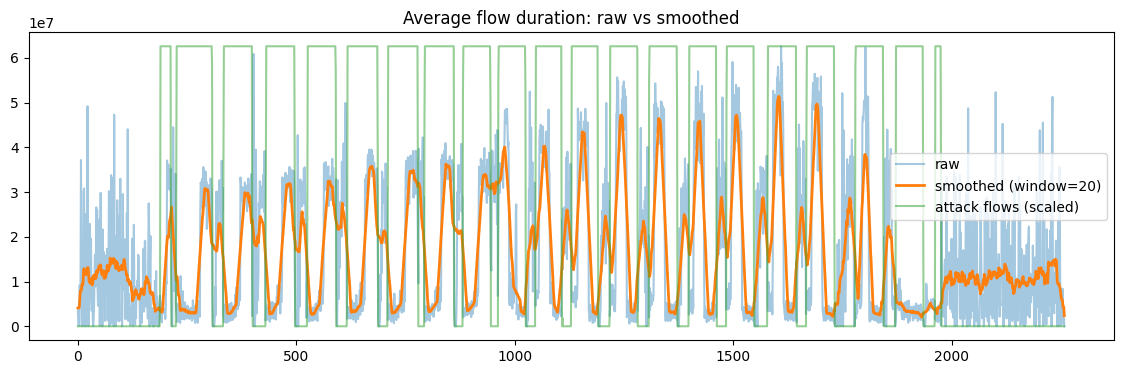

In [66]:
import numpy as np

signal = duration_signal.values
kernel = np.ones(20) / 20
smoothed = np.convolve(signal, kernel, mode='same')

plt.figure(figsize=(14, 4))
plt.plot(signal, label='raw', alpha=0.4)
plt.plot(smoothed, label='smoothed (window=20)', linewidth=2)
plt.plot(attack_mask.values * (signal.max() / attack_mask.max()), label='attack flows (scaled)', alpha=0.5)
plt.legend()
plt.title('Average flow duration: raw vs smoothed')
plt.show()

In [58]:
true_attack = attack_mask.values > 50
threshold = 2e7
predicted = smoothed > threshold

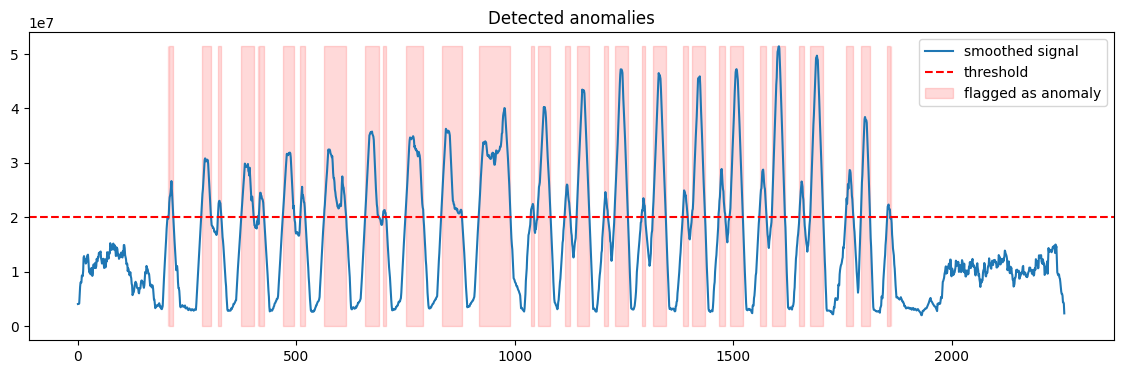

In [59]:
plt.figure(figsize=(14, 4))
plt.plot(smoothed, label='smoothed signal')
plt.axhline(threshold, color='red', linestyle='--', label='threshold')
plt.fill_between(range(len(smoothed)), 0, smoothed.max(), where=predicted, color='red', alpha=0.15, label='flagged as anomaly')
plt.legend()
plt.title('Detected anomalies')
plt.show()

In [60]:
TP = np.sum(predicted & true_attack)
FP = np.sum(predicted & ~true_attack)
FN = np.sum(~predicted & true_attack)

precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)

print('TP', TP, 'FP', FP, 'FN', FN)
print('Precision', round(precision, 3), 'Recall', round(recall, 3), 'F1', round(f1, 3))

TP 512 FP 245 FN 766
Precision 0.676 Recall 0.401 F1 0.503


threshold    5.000000e+06
precision    4.892443e-01
recall       6.940532e-01
f1           5.739243e-01
Name: 0, dtype: float64


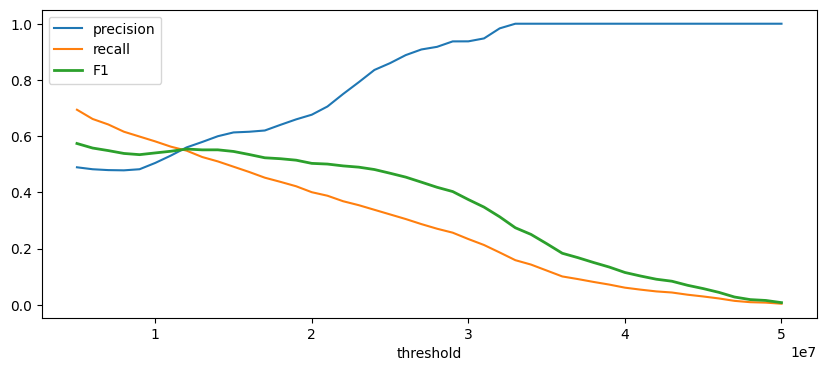

In [61]:
import pandas as pd

rows = []
for t in np.linspace(0.5e7, 5e7, 46):
    pred = smoothed > t
    TP = np.sum(pred & true_attack)
    FP = np.sum(pred & ~true_attack)
    FN = np.sum(~pred & true_attack)
    p = TP / (TP + FP) if (TP + FP) > 0 else 0
    r = TP / (TP + FN) if (TP + FN) > 0 else 0
    f = 2 * p * r / (p + r) if (p + r) > 0 else 0
    rows.append((t, p, r, f))

results = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])
print(results.loc[results['f1'].idxmax()])

plt.figure(figsize=(10, 4))
plt.plot(results['threshold'], results['precision'], label='precision')
plt.plot(results['threshold'], results['recall'], label='recall')
plt.plot(results['threshold'], results['f1'], label='F1', linewidth=2)
plt.xlabel('threshold')
plt.legend()
plt.show()


In [62]:
from scipy.ndimage import label

blocks, n_blocks = label(true_attack)
caught = sum(predicted[blocks == i].any() for i in range(1, n_blocks + 1))
print(caught, 'of', n_blocks, 'attack blocks have at least one flagged bin')


19 of 21 attack blocks have at least one flagged bin


In [63]:
pred_blocks, n_pred = label(predicted)
false_alarms = sum(not true_attack[pred_blocks == i].any() for i in range(1, n_pred + 1))
print(false_alarms, 'of', n_pred, 'flagged segments contain no attack bins')

16 of 35 flagged segments contain no attack bins


In [64]:
for i in range(1, n_pred + 1):
    idx = np.where(pred_blocks == i)[0]
    if not true_attack[idx].any():
        near = true_attack[max(0, idx[0] - 10): idx[-1] + 11].any()
        print(f'bins {idx[0]}-{idx[-1]} (length {len(idx)}), attack within 10 bins: {near}')

bins 321-328 (length 8), attack within 10 bins: True
bins 412-412 (length 1), attack within 10 bins: False
bins 414-426 (length 13), attack within 10 bins: True
bins 509-520 (length 12), attack within 10 bins: True
bins 698-704 (length 7), attack within 10 bins: True
bins 1036-1043 (length 8), attack within 10 bins: True
bins 1114-1126 (length 13), attack within 10 bins: True
bins 1204-1212 (length 9), attack within 10 bins: True
bins 1290-1298 (length 9), attack within 10 bins: True
bins 1384-1395 (length 12), attack within 10 bins: True
bins 1466-1481 (length 16), attack within 10 bins: True
bins 1560-1575 (length 16), attack within 10 bins: True
bins 1651-1662 (length 12), attack within 10 bins: True
bins 1757-1774 (length 18), attack within 10 bins: True
bins 1852-1858 (length 7), attack within 10 bins: True
bins 1860-1861 (length 2), attack within 10 bins: False


In [65]:
import pandas as pd
from scipy.ndimage import label

true_attack = attack_mask.values > 50
signal = duration_signal.values

def evaluate(window, threshold=2e7):
    sm = np.convolve(signal, np.ones(window) / window, mode='same')
    pred = sm > threshold
    TP = np.sum(pred & true_attack)
    FP = np.sum(pred & ~true_attack)
    FN = np.sum(~pred & true_attack)
    p = TP / (TP + FP) if TP + FP > 0 else 0
    r = TP / (TP + FN) if TP + FN > 0 else 0
    f = 2 * p * r / (p + r) if p + r > 0 else 0
    ab, n_ab = label(true_attack)
    caught = sum(pred[ab == i].any() for i in range(1, n_ab + 1))
    pb, n_pb = label(pred)
    false_seg = sum(not true_attack[pb == i].any() for i in range(1, n_pb + 1))
    return dict(window=window, precision=round(p, 3), recall=round(r, 3), f1=round(f, 3),
                attacks_caught=f'{caught}/{n_ab}', flagged_segments=n_pb, false_segments=false_seg)

pd.DataFrame([evaluate(w) for w in [1, 5, 10, 20]])

,window,precision,recall,f1,attacks_caught,flagged_segments,false_segments
0,1,0.572,0.370,0.449,19/21,149,129
1,5,0.622,0.378,0.470,19/21,43,25
2,10,0.644,0.382,0.479,19/21,36,18
3,20,0.676,0.401,0.503,19/21,35,16


In [67]:
from sklearn.metrics import roc_auc_score
for w in [1, 5, 10, 20]:
    sm = np.convolve(signal, np.ones(w) / w, mode='same')
    print('window', w, 'AUC', round(roc_auc_score(true_attack, sm), 3))

window 1 AUC 0.514
window 5 AUC 0.442
window 10 AUC 0.448
window 20 AUC 0.504
